
# **Loan Credit Risk Engine**

This project is built around the Kaggle Home Credit Default Risk Competition.

Many people struggle to get loans due to insufficient or non-existent credit histories. Home Credit strives to broaden financial inclusion for the unbanked population by providing a safe and positive borrowing experience. The objective of this project is to build a machine learning classification model to predict an applicant's repayment capability, ensuring that clients capable of repayment are successfully identified and granted loans.

## **Exploratory Data Analysis**

## 1. Importing Libraries

In [15]:
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt

In [13]:
# Reading data from file
df = pd.read_csv("../../data/application_train.csv", nrows=10000)

target_column = 'TARGET'
# Split into train (80%) and test (20%)
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df[target_column]
)

print(f'Train set: {train_df.shape[0]} rows ({(len(train_df) / len(df)) * 100:.1f}%)')
print(f'Test set: {test_df.shape[0]} rows ({(len(test_df) / len(df)) * 100:.1f}%)')

#Compare class distribution
print(f"\nOriginal Target Distribution:")
print(df[target_column].value_counts(normalize=True))

print("\nTrain Target Distribution:")
print(train_df[target_column].value_counts(normalize=True))

print("\nTest Target Distribution:")
print(test_df[target_column].value_counts(normalize=True))



Train set: 8000 rows (80.0%)
Test set: 2000 rows (20.0%)

Original Target Distribution:
TARGET
0    0.9225
1    0.0775
Name: proportion, dtype: float64

Train Target Distribution:
TARGET
0    0.9225
1    0.0775
Name: proportion, dtype: float64

Test Target Distribution:
TARGET
0    0.9225
1    0.0775
Name: proportion, dtype: float64


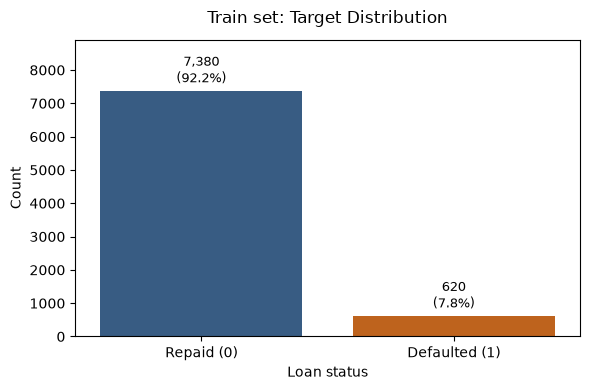

In [48]:
# Bar plot showing the counts of 0 and 1

plt.figure(figsize=(6, 4))
ax = sns.countplot(
    data=train_df,
    x=target_column,
    hue=target_column,
    palette=['#2b5c8f', '#d95f02'],
    legend=False
)

plt.title('Train set: Target Distribution', pad=12)
plt.xlabel('Loan status')
plt.ylabel('Count')
plt.xticks(ticks=[0, 1], labels=['Repaid (0)', 'Defaulted (1)'])

total = len(train_df)
for p in ax.patches:
    height = p.get_height()
    percentage = f'{100 * height / total:.1f}%'
    ax.annotate(
        f'{int(height):,}\n({percentage})',
        (p.get_x() + p.get_width() / 2., height),
        ha='center',
        va='bottom',
        fontsize=9,
        xytext=(0, 3),
        textcoords='offset points'
    )

curr_bottom, curr_top = ax.get_ylim()
ax.set_ylim(curr_bottom, curr_top * 1.15)

plt.tight_layout()
plt.show()



Minimum age: 21.1 years
Maximum age: 68.9 years


Minimum age: 21.1 years
Maximum age: 68.9 years


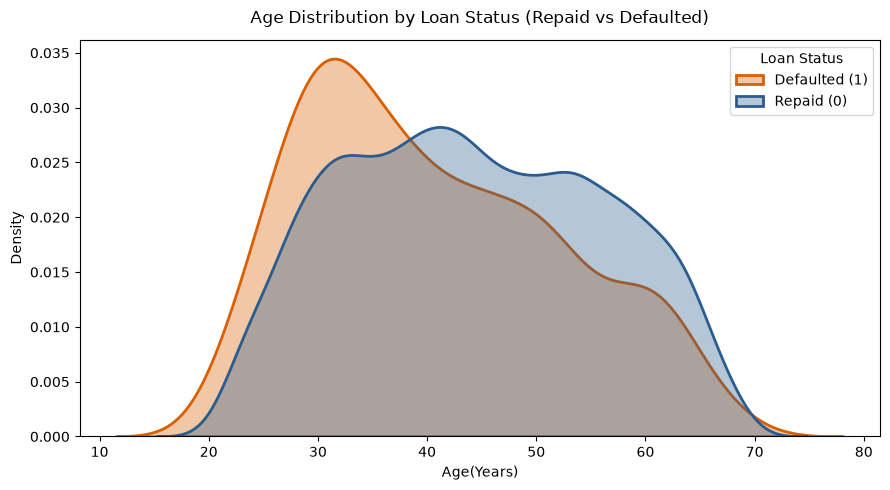

In [74]:
# Converting Age to Years
train_df['AGE_YEARS'] = - train_df['DAYS_BIRTH'] / 365.25

print(f'Minimum age: {train_df['AGE_YEARS'].min():.1f} years')
print(f'Maximum age: {train_df['AGE_YEARS'].max():.1f} years')


#Visualizing Age vs Default
plt.figure(figsize=(9, 5))

sns.kdeplot(
    data=train_df,
    x='AGE_YEARS',
    hue='TARGET',
    palette=['#2b5c8f', '#d95f02'],
    fill=True,
    common_norm=False,
    alpha=0.35,
    linewidth=2
)

plt.title('Age Distribution by Loan Status (Repaid vs Defaulted)', pad=12)
plt.xlabel('Age(Years)')
plt.ylabel('Density')

plt.legend(title='Loan Status', labels=['Defaulted (1)', 'Repaid (0)'])

plt.tight_layout()
plt.show()


Days Employed: 1774


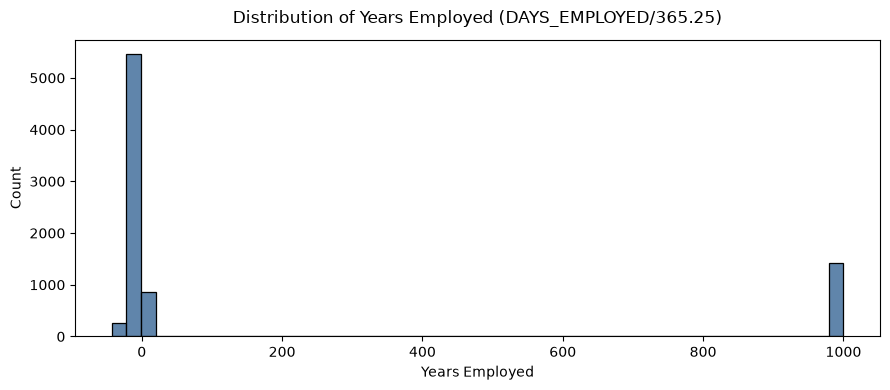

In [94]:
anomaly_count = (df['DAYS_EMPLOYED'] == 365243).sum()
print(f'Days Employed: {anomaly_count}')

#Visualizing Days Employed
plt.figure(figsize=(9,4))

years_employed = train_df['DAYS_EMPLOYED']/365.25

sns.histplot(
    years_employed,
    bins=50,
    color='#2b5c8f',
    edgecolor='black'
)

plt.title('Distribution of Years Employed (DAYS_EMPLOYED/365.25)', pad=12)
plt.xlabel('Years Employed')
plt.ylabel('Count')

plt.tight_layout()
plt.show()
